In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import datasets as dt
import sklearn as sk

# huggingface_dataset = dt.load_dataset("electricsheepafrica/african-hypertension-cvd-dataset")
huggingface_dataset = dt.load_dataset("electricsheepafrica/africa-synth-hypertension-hypertension-cvd-dataset-all")

# Convert to Pandas
data_train = huggingface_dataset["train"].to_pandas()
dataset = data_train.to_csv("hypertension_datasettt.csv", index=False)

val_df = huggingface_dataset["validation"].to_pandas()
test_df = huggingface_dataset["test"].to_pandas()

In [26]:
# Copy the data
df = data_train.copy()
df_val = val_df.copy()
df_test = test_df.copy()

In [27]:
print("Train shape    :", df.shape)
print("Validate shape :", df_val.shape)
print("Test shape     :", df_test.shape)

Train shape    : (10000, 25)
Validate shape : (5000, 25)
Test shape     : (2000, 25)


# Full EDA To Train Data Only (Exploratriy Data Analysis)

In [28]:
#  Basic inspection
# ========================= #

print("First 5 rows:")
df.head()
# df_val.head()
df_test.head()



First 5 rows:


,patient_id,age,sex,residence,bmi,family_history_hypertension,diabetes,smoking,alcohol_heavy,physically_active,...,on_medication,medication_adherence,bp_controlled,stroke_history,myocardial_infarction,heart_failure,total_cholesterol_mg_dl,ldl_mg_dl,hdl_mg_dl,creatinine_mg_dl
0,HTN_000001,57.2,Female,Rural,24.1,False,False,False,False,False,...,False,None,False,False,False,False,243.0,138.0,67.0,1.19
1,HTN_000002,72.7,Female,Rural,24.4,False,False,True,False,False,...,False,Undiagnosed,False,False,False,False,221.0,190.0,74.0,1.43
2,HTN_000003,38.2,Female,Rural,26.0,False,False,False,False,False,...,False,Undiagnosed,False,True,False,False,201.0,191.0,52.0,1.50
3,HTN_000004,39.9,Female,Rural,23.9,False,False,False,False,True,...,False,Undiagnosed,False,True,False,False,230.0,158.0,47.0,0.92
4,HTN_000005,50.2,Male,Rural,17.7,False,False,True,False,True,...,False,Undiagnosed,False,False,False,False,147.0,139.0,42.0,1.28


In [29]:

print("\nShape of dataset:")
print(df.shape)





Shape of dataset:
(10000, 25)


In [30]:
print("\nColumn names:")
df.columns.tolist()




Column names:


['patient_id',
 'age',
 'sex',
 'residence',
 'bmi',
 'family_history_hypertension',
 'diabetes',
 'smoking',
 'alcohol_heavy',
 'physically_active',
 'high_salt_diet',
 'hypertension_status',
 'systolic_bp_mmhg',
 'diastolic_bp_mmhg',
 'diagnosed',
 'on_medication',
 'medication_adherence',
 'bp_controlled',
 'stroke_history',
 'myocardial_infarction',
 'heart_failure',
 'total_cholesterol_mg_dl',
 'ldl_mg_dl',
 'hdl_mg_dl',
 'creatinine_mg_dl']

In [31]:
print("\nData types:")
df.dtypes




Data types:


,0
patient_id,object
age,float64
sex,object
residence,object
bmi,float64
family_history_hypertension,bool
diabetes,bool
smoking,bool
alcohol_heavy,bool
physically_active,bool


In [32]:
print("\nMissing values:")
df.isnull().sum()




Missing values:


,0
patient_id,0
age,0
sex,0
residence,0
bmi,0
family_history_hypertension,0
diabetes,0
smoking,0
alcohol_heavy,0
physically_active,0


In [33]:
print("\nNumber of duplicate rows:")
df.duplicated().sum()


Number of duplicate rows:


np.int64(0)

Data Leakage:

Data Leakage = when model learns from information it should NOT have.

Result:

Fake high accuracy,
Model fails in real-world.

Because My platform is supposed to predict hypertension risk from user-entered information, not from direct diagnosis-related or post-diagnosis variables.

If I keep these columns, the model may achieve very high performance, but it will be misleading. That is called data leakage.




In [34]:
# Because Data leakage
cols_to_drop = [
    "systolic_bp_mmhg",
    "diastolic_bp_mmhg",
    "bp_controlled",
    "diagnosed",
    "on_medication",
    "medication_adherence",
    "patient_id"

]


In [35]:
df.columns

Index(['patient_id', 'age', 'sex', 'residence', 'bmi',
       'family_history_hypertension', 'diabetes', 'smoking', 'alcohol_heavy',
       'physically_active', 'high_salt_diet', 'hypertension_status',
       'systolic_bp_mmhg', 'diastolic_bp_mmhg', 'diagnosed', 'on_medication',
       'medication_adherence', 'bp_controlled', 'stroke_history',
       'myocardial_infarction', 'heart_failure', 'total_cholesterol_mg_dl',
       'ldl_mg_dl', 'hdl_mg_dl', 'creatinine_mg_dl'],
      dtype='object')

In [36]:
df["hypertension_status"]

,hypertension_status
0,Hypertensive
1,Hypertensive
2,Hypertensive
3,Hypertensive
4,Normal
...,...
9995,Hypertensive
9996,Normal
9997,Hypertensive
9998,Hypertensive


In [37]:
# =========================
#  Separate feature types
# =========================
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "bool"]).columns.tolist()

# Remove target from numerical list if present
if "hypertension_status" in numerical_cols:
    numerical_cols.remove("hypertension_status")

print("\nNumerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)



Numerical columns:
['age', 'bmi', 'systolic_bp_mmhg', 'diastolic_bp_mmhg', 'total_cholesterol_mg_dl', 'ldl_mg_dl', 'hdl_mg_dl', 'creatinine_mg_dl']

Categorical columns:
['patient_id', 'sex', 'residence', 'family_history_hypertension', 'diabetes', 'smoking', 'alcohol_heavy', 'physically_active', 'high_salt_diet', 'hypertension_status', 'diagnosed', 'on_medication', 'medication_adherence', 'bp_controlled', 'stroke_history', 'myocardial_infarction', 'heart_failure']


In [38]:
# =========================
#  Summary statistics
# =========================
print("\nNumerical summary:")
print(df[numerical_cols].describe())

print("______________________________________________")
print("______________________________________________")

print("\nCategorical/Boolean summary:")
for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())



Numerical summary:
                age           bmi  systolic_bp_mmhg  diastolic_bp_mmhg  \
count  10000.000000  10000.000000       10000.00000       10000.000000   
mean      47.950980     25.241360         146.09740          91.363500   
std       14.569781      4.547277          20.32469          13.081815   
min       18.000000     16.000000          90.00000          60.000000   
25%       37.800000     22.000000         130.00000          81.000000   
50%       47.900000     25.200000         147.00000          91.000000   
75%       58.300000     28.300000         160.00000         101.000000   
max       85.000000     42.700000         200.00000         120.000000   

       total_cholesterol_mg_dl    ldl_mg_dl    hdl_mg_dl  creatinine_mg_dl  
count             10000.000000  10000.00000  10000.00000      10000.000000  
mean                204.707100    135.32890     47.08050          1.145046  
std                  40.302649     35.88074     11.86593          0.374146  
min  

In [39]:
# to Know If exist Balance in the Target
df["hypertension_status"].value_counts()

,count
hypertension_status,
Hypertensive,8105
Normal,1895


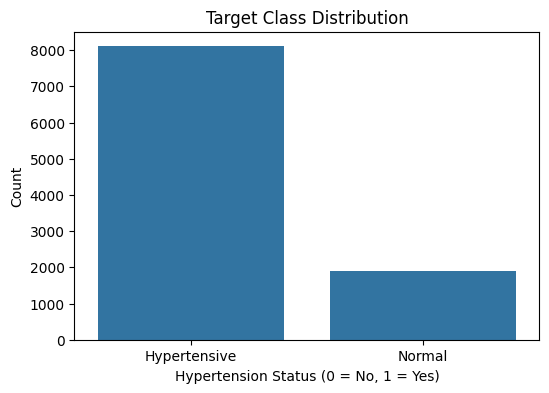

In [40]:
# =========================
#  Class distribution
# =========================
plt.figure(figsize=(6, 4))
sns.countplot(x="hypertension_status", data=df)
plt.title("Target Class Distribution")
plt.xlabel("Hypertension Status (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


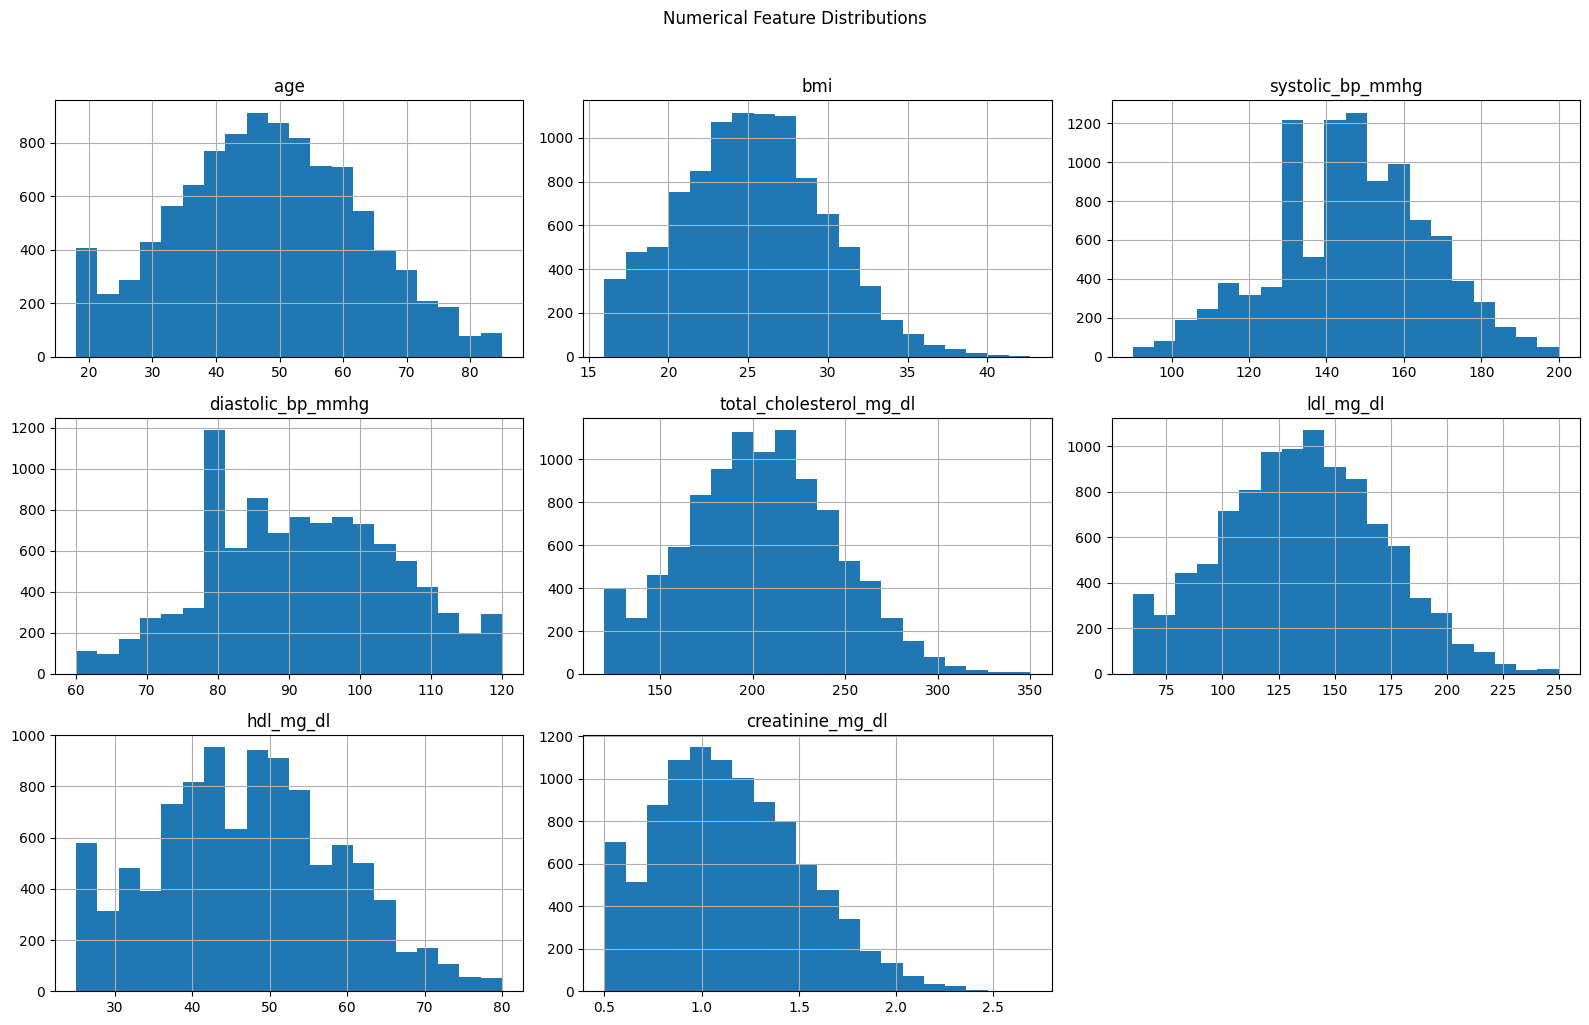

In [41]:
# =========================
#  Histograms for numerical features
# =========================
df[numerical_cols].hist(figsize=(16, 10), bins=20)
plt.suptitle("Numerical Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()


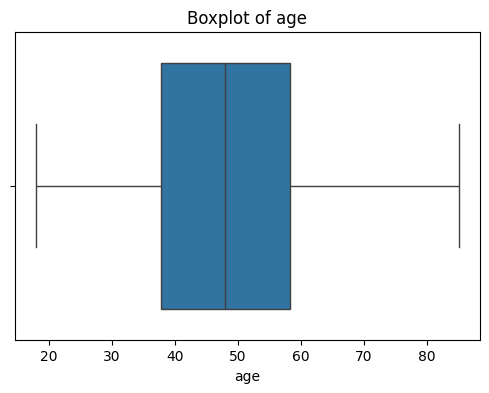

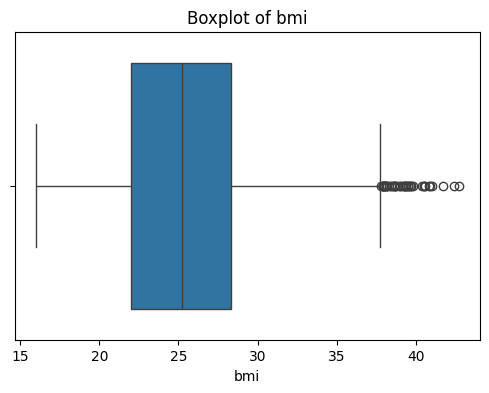

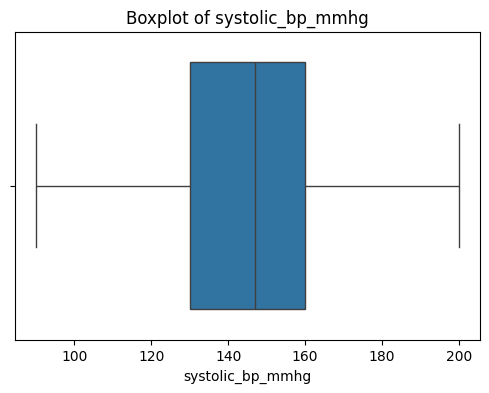

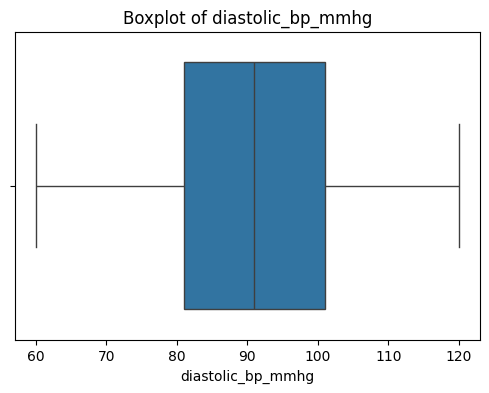

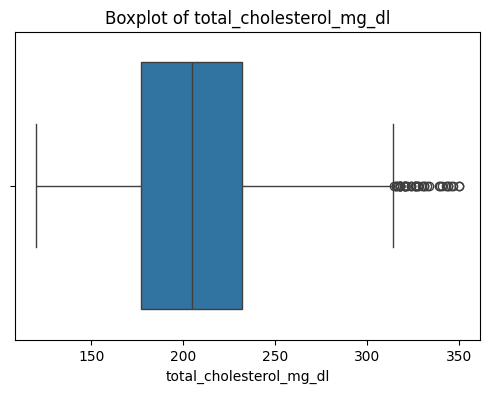

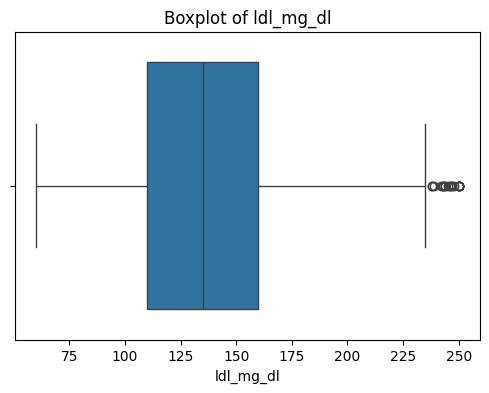

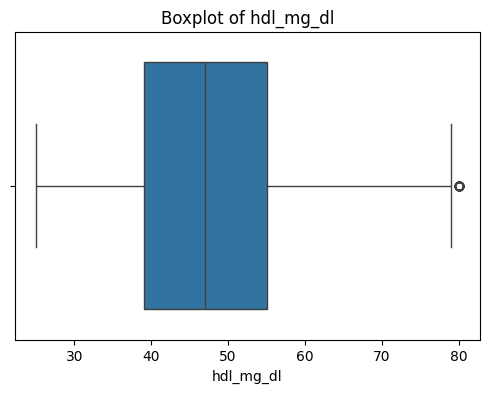

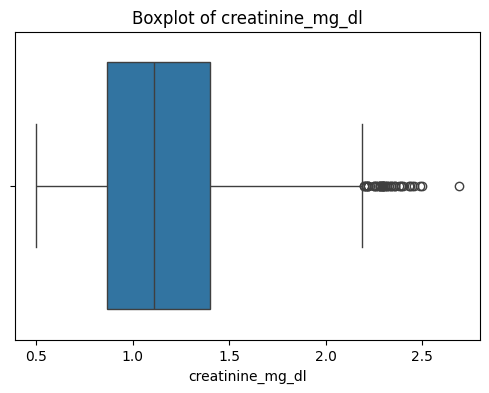

In [42]:
# =========================
#  Boxplots for outlier inspection
# =========================
for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


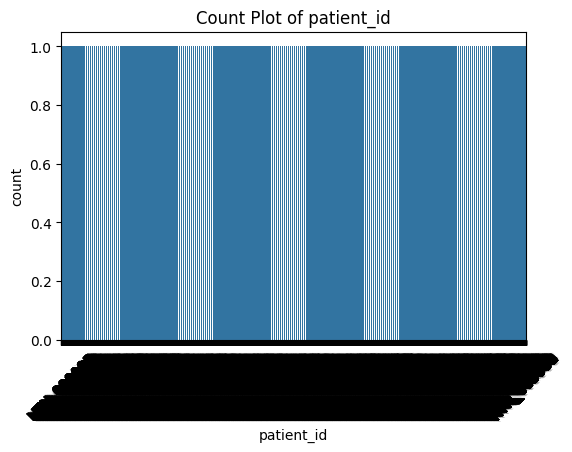

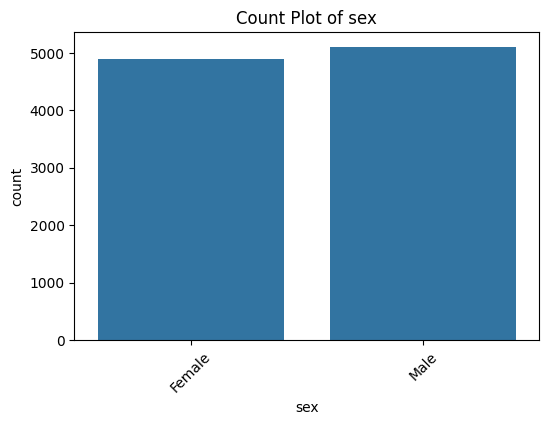

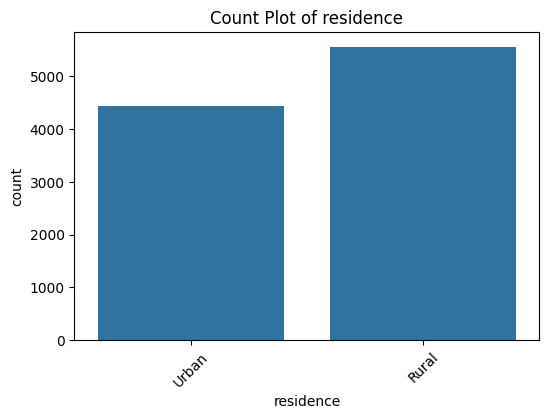

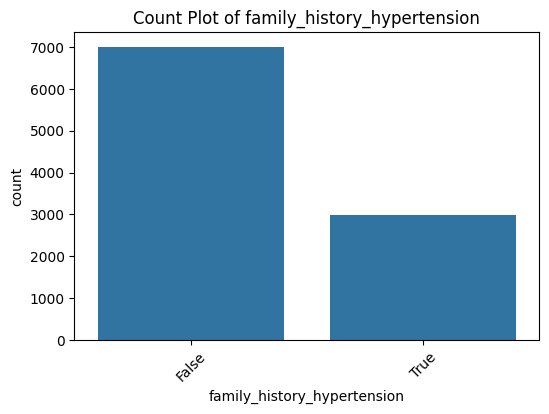

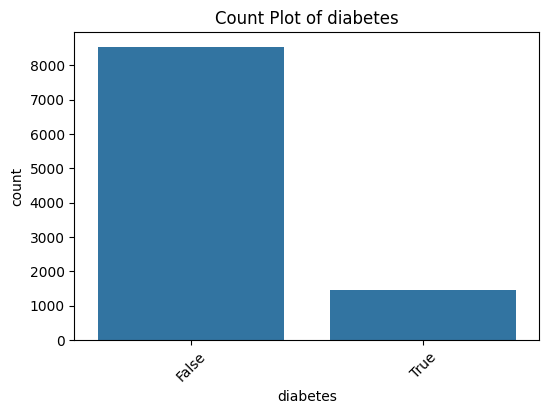

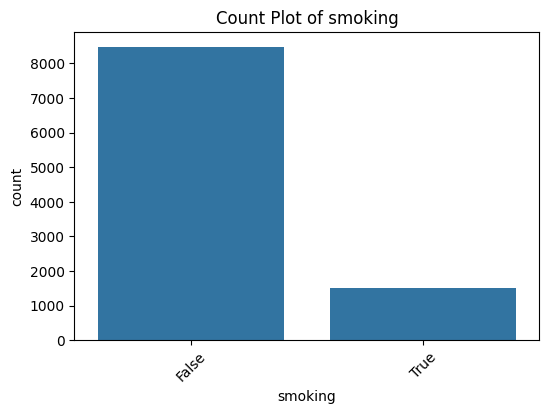

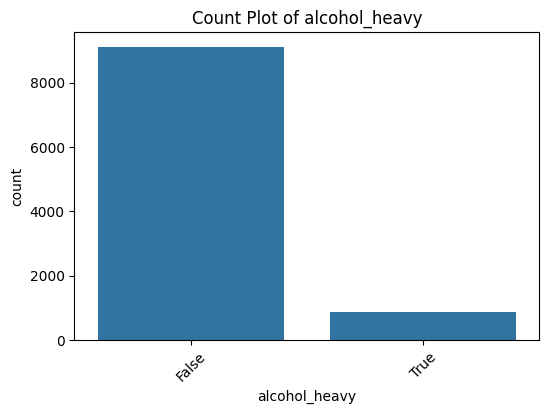

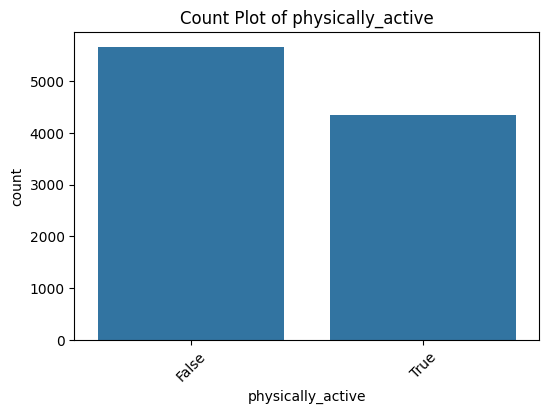

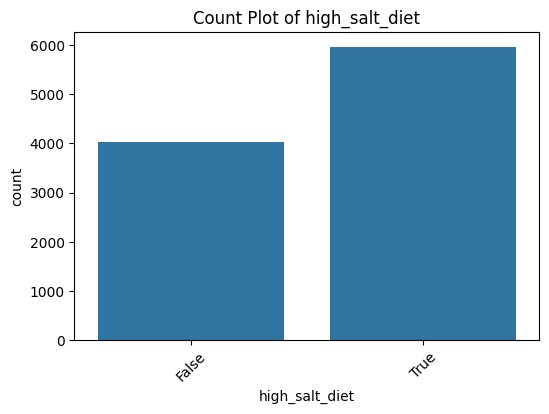

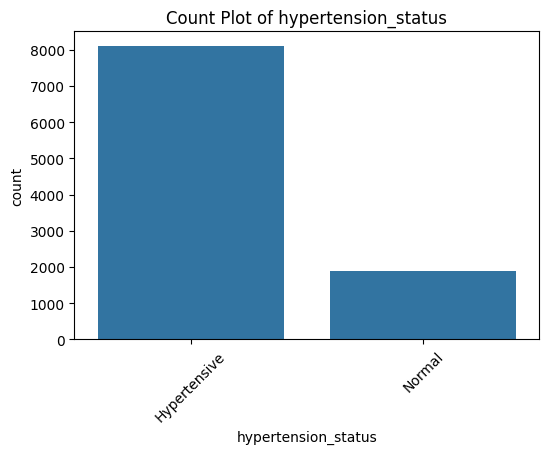

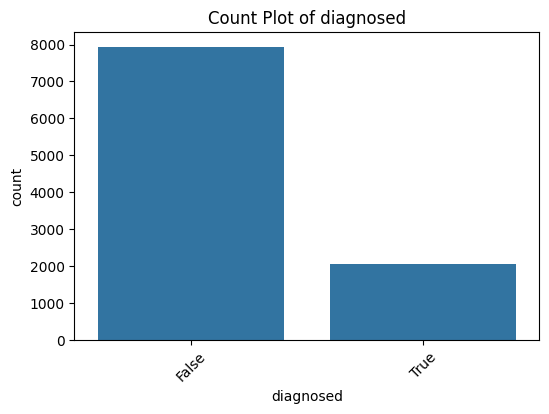

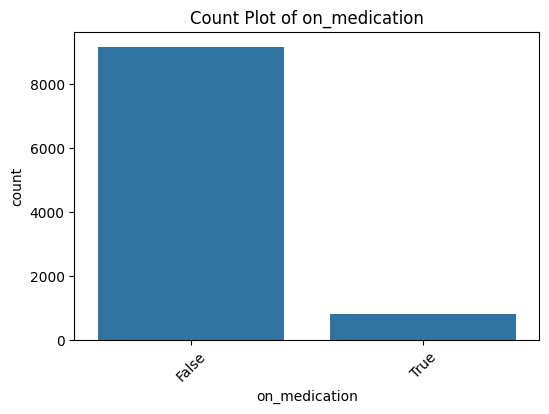

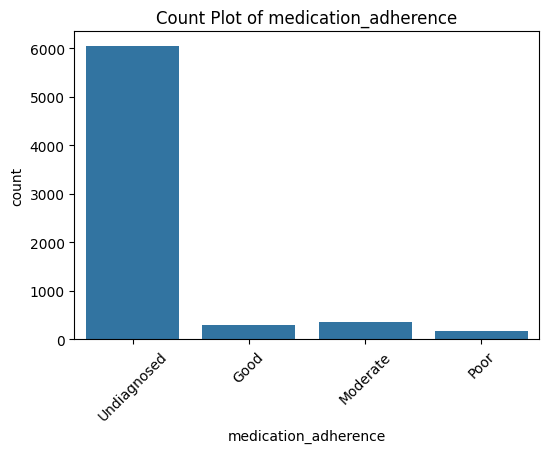

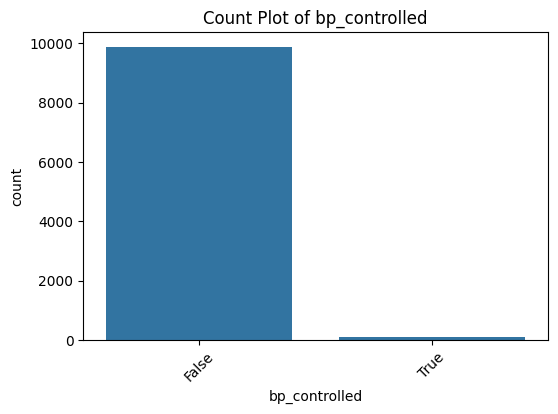

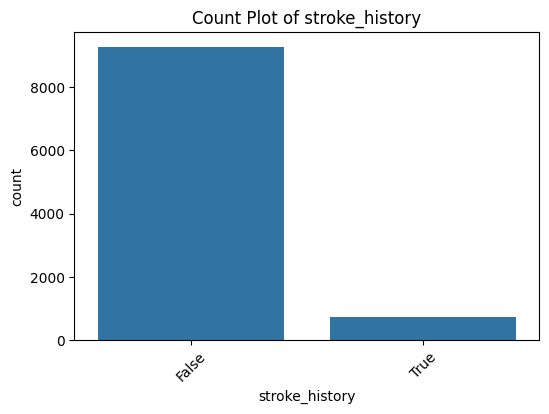

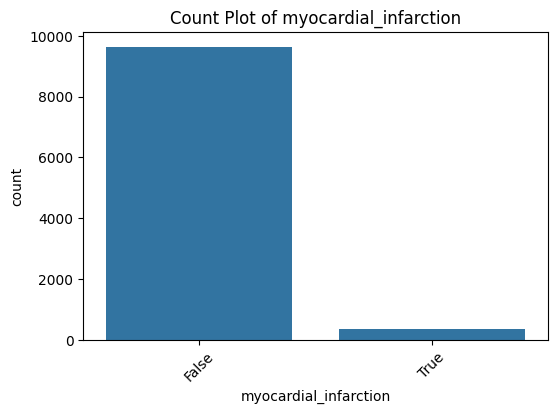

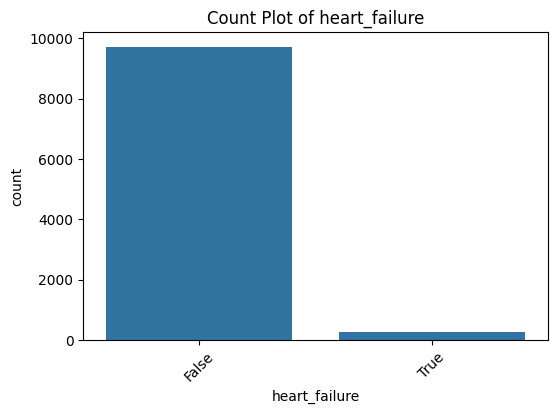

In [43]:
# =========================
#  Countplots for categorical/boolean features
# =========================
for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col, data=df)
    plt.title(f"Count Plot of {col}")
    plt.xticks(rotation=45)
    plt.show()


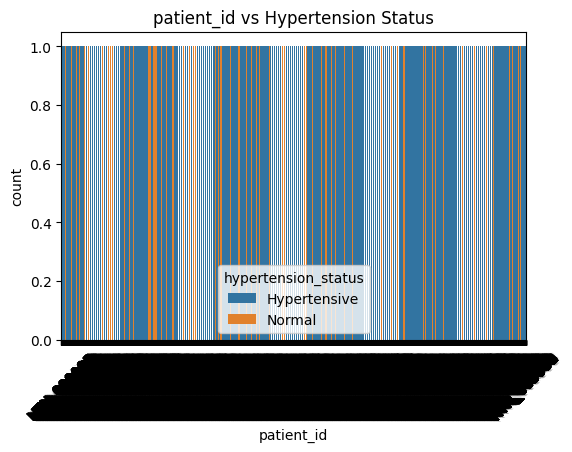

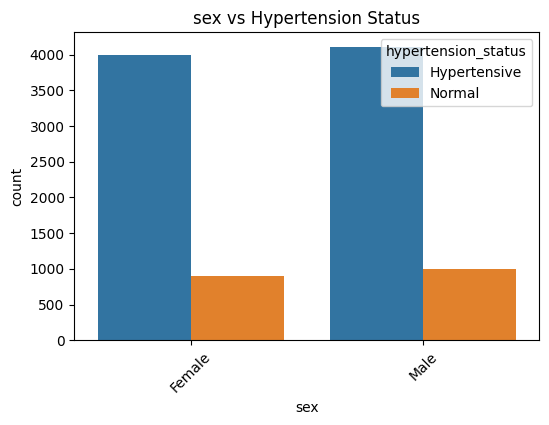

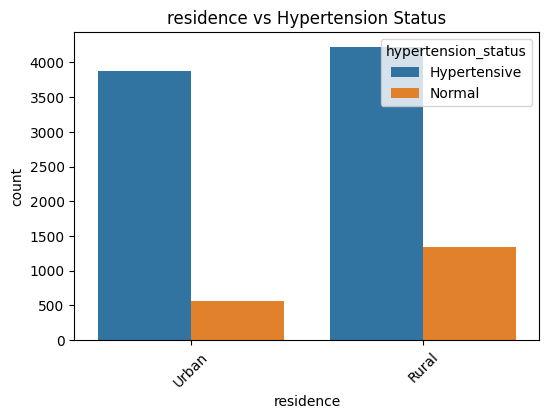

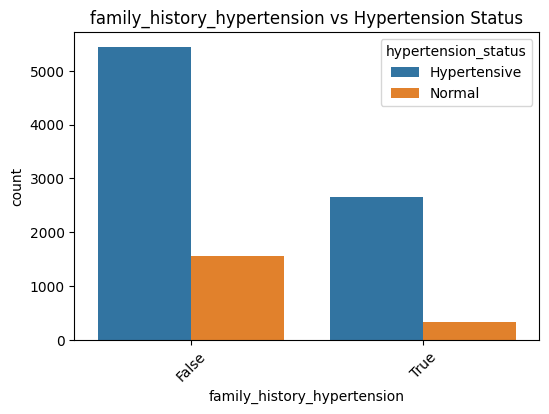

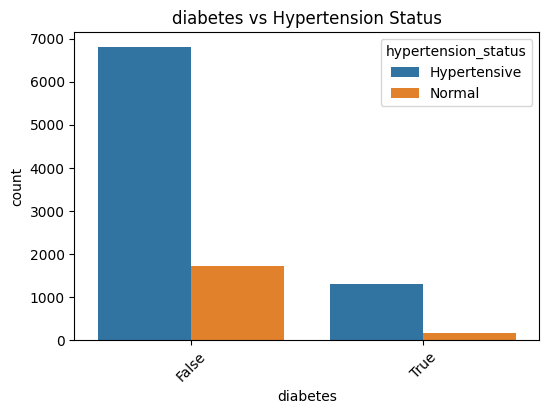

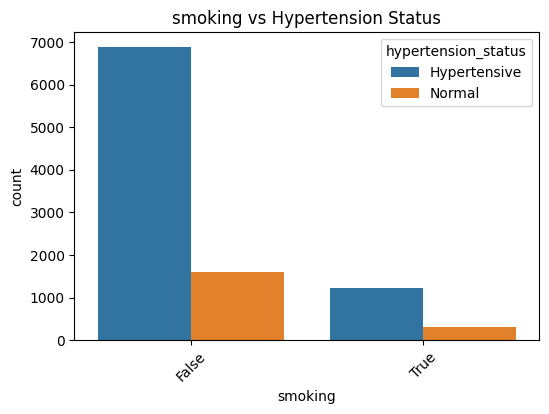

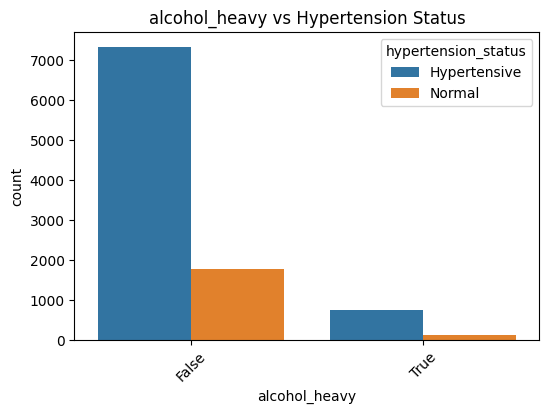

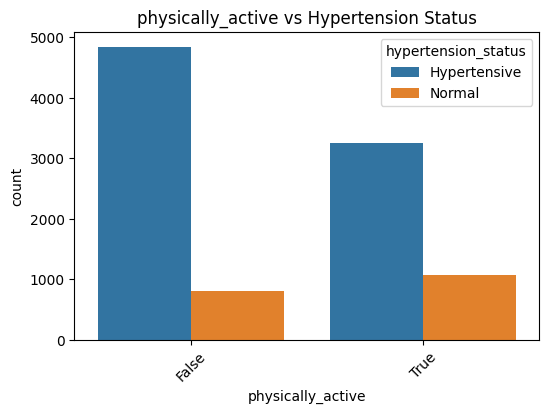

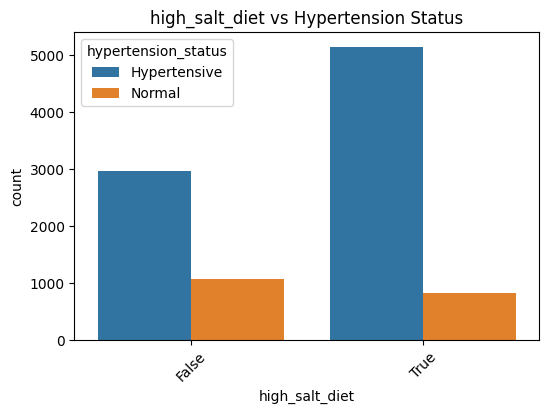

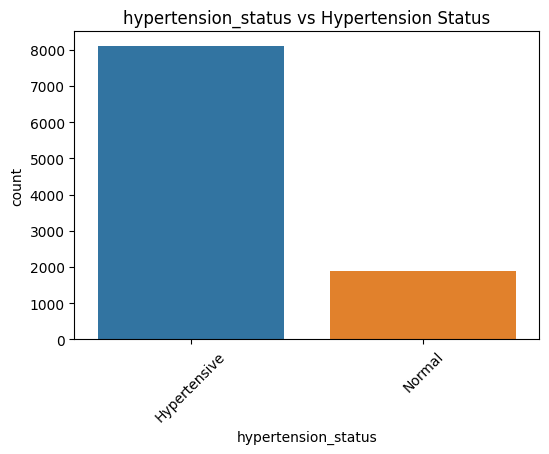

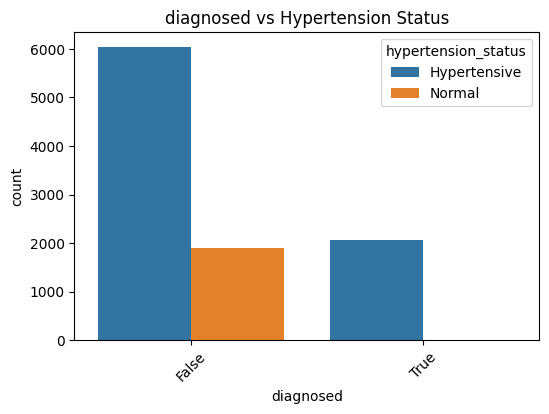

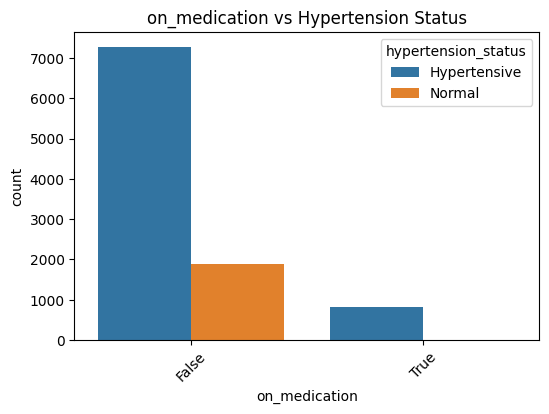

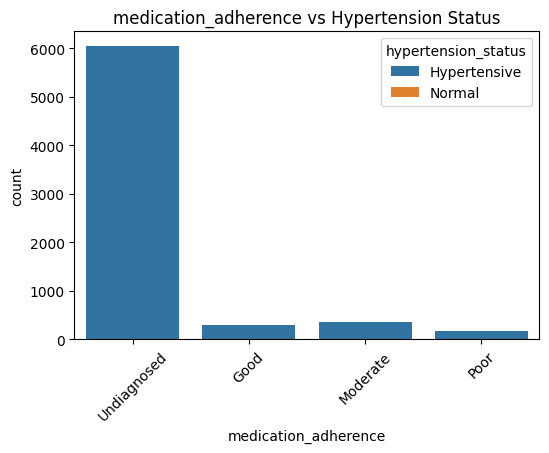

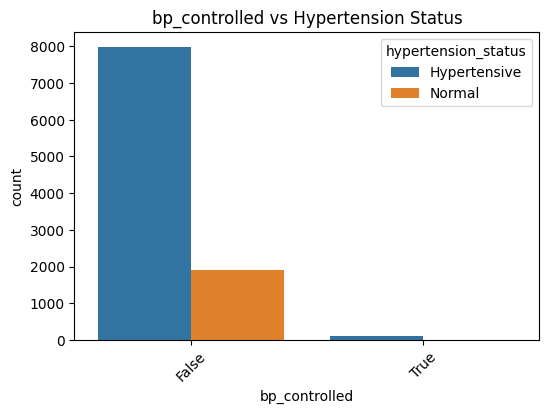

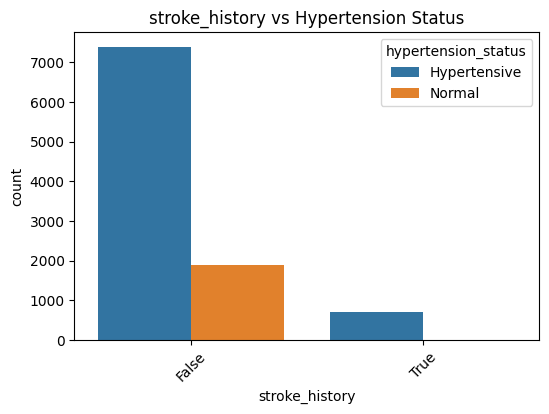

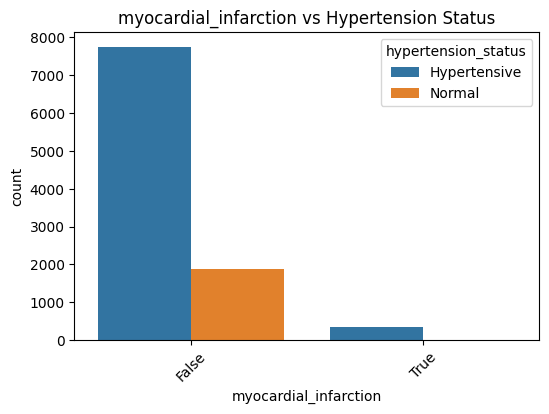

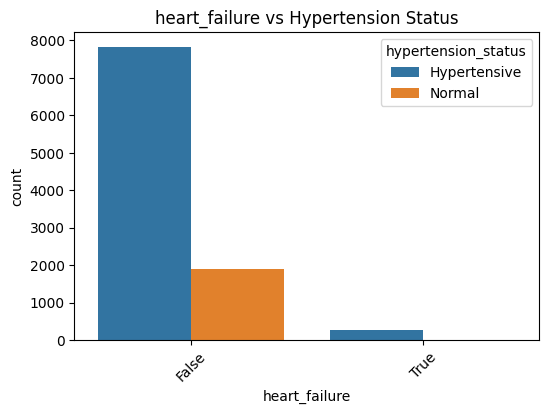

In [44]:
# =========================
# Feature vs target analysis (categorical/boolean)
# =========================
for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col, hue="hypertension_status", data=df)
    plt.title(f"{col} vs Hypertension Status")
    plt.xticks(rotation=45)
    plt.show()

In [45]:
# To show Percentace
#===============================

for col in categorical_cols:
    print(f"\n===== {col} vs Hypertension =====")

    table = pd.crosstab(
        df[col],
        df["hypertension_status"],
        normalize="index"
    )

    print(table)


===== patient_id vs Hypertension =====
hypertension_status  Hypertensive  Normal
patient_id                               
HTN_000001                    1.0     0.0
HTN_000002                    1.0     0.0
HTN_000003                    1.0     0.0
HTN_000004                    1.0     0.0
HTN_000005                    0.0     1.0
...                           ...     ...
HTN_009996                    1.0     0.0
HTN_009997                    0.0     1.0
HTN_009998                    1.0     0.0
HTN_009999                    1.0     0.0
HTN_010000                    0.0     1.0

[10000 rows x 2 columns]

===== sex vs Hypertension =====
hypertension_status  Hypertensive    Normal
sex                                        
Female                   0.817123  0.182877
Male                     0.804152  0.195848

===== residence vs Hypertension =====
hypertension_status  Hypertensive    Normal
residence                                  
Rural                    0.760072  0.239928
Urban   

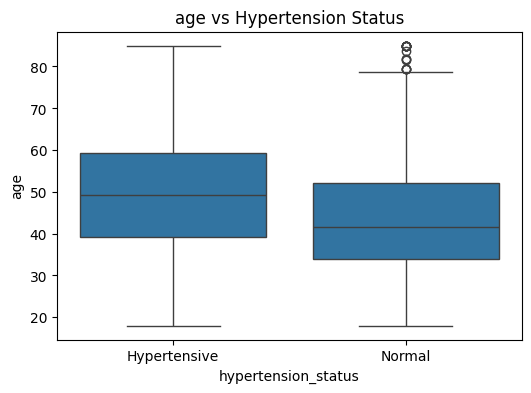

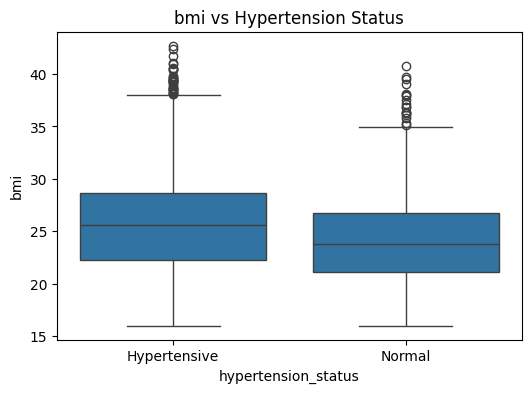

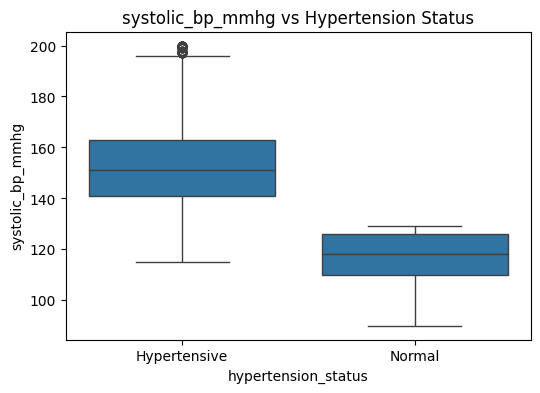

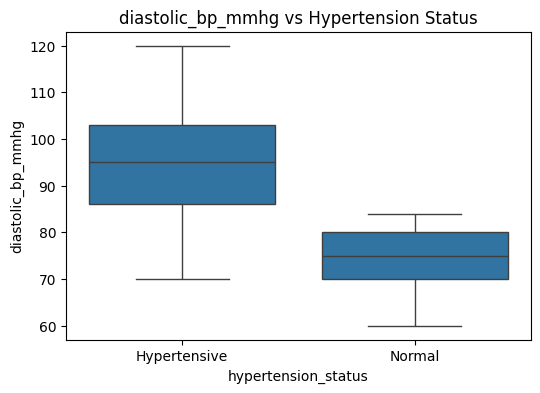

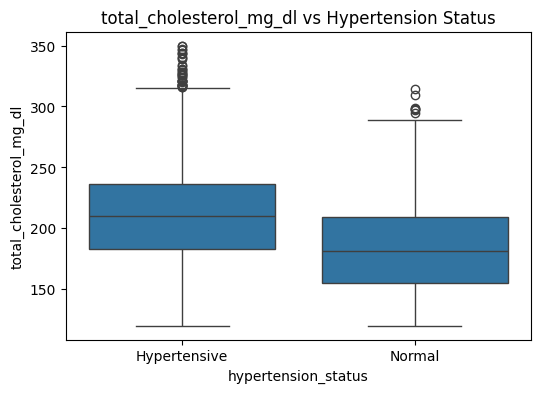

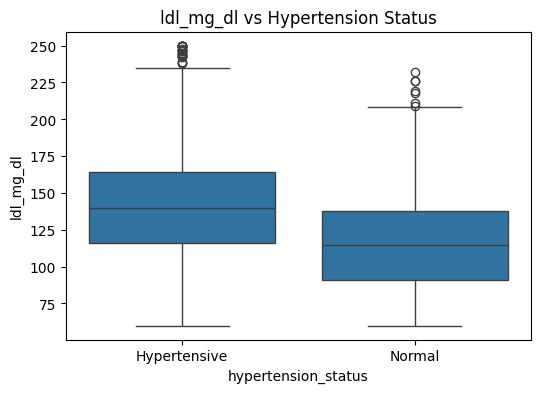

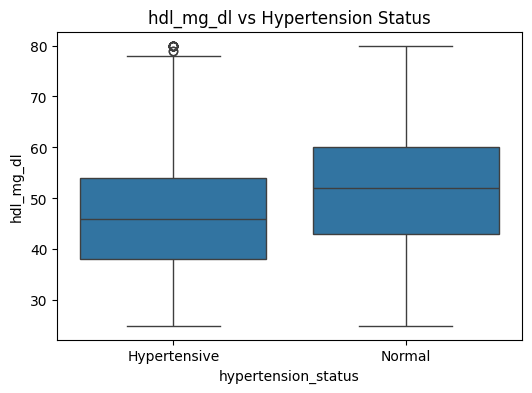

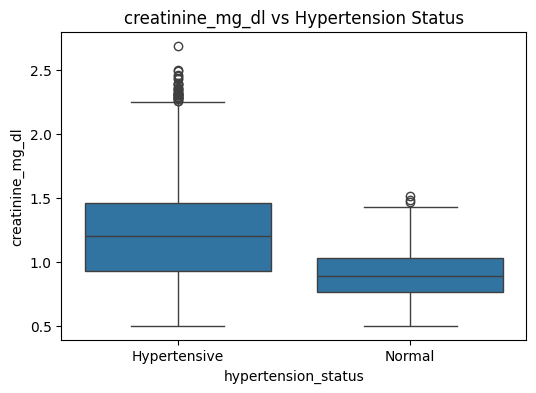

In [97]:
# =========================
# Numerical features vs target
# =========================
for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x="hypertension_status", y=col, data=df)
    plt.title(f"{col} vs Hypertension Status")
    plt.show()

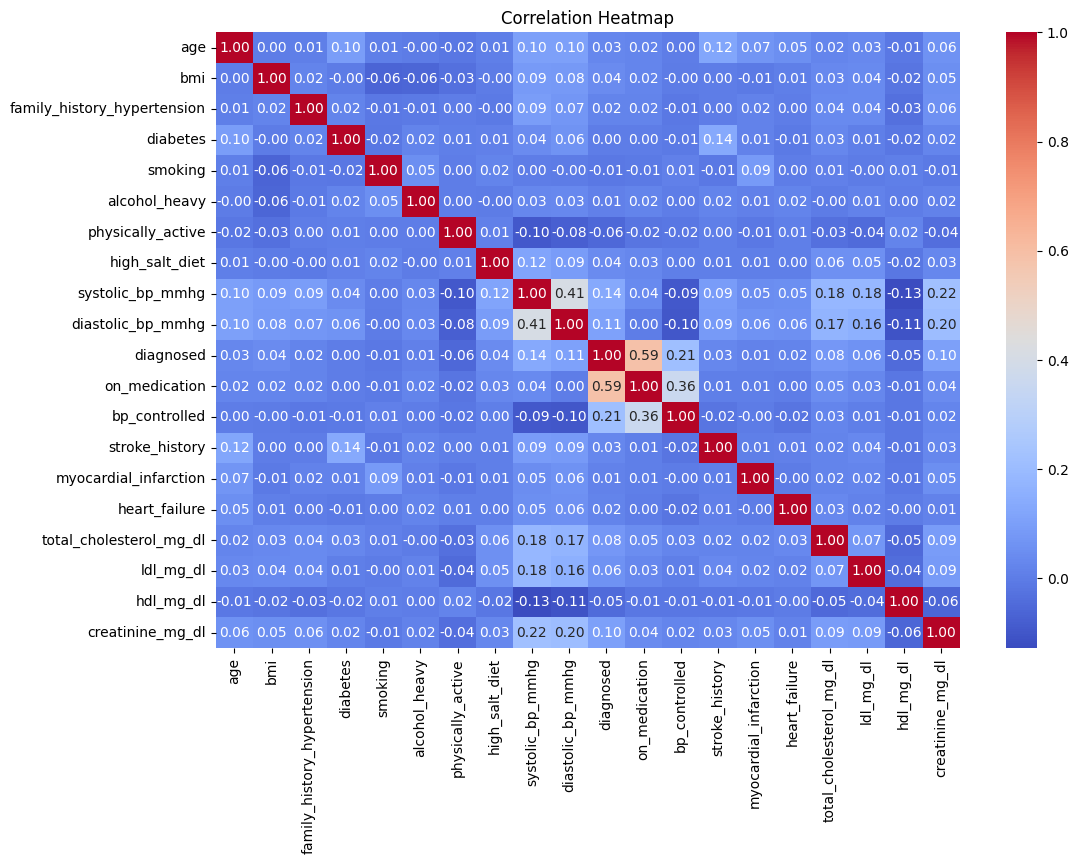

In [98]:
# =========================
# Correlation heatmap
# =========================
# Convert boolean columns to integers temporarily for correlation
df_corr = df.copy()
bool_cols = df_corr.select_dtypes(include=["bool"]).columns

for col in bool_cols:
    df_corr[col] = df_corr[col].astype(int)

plt.figure(figsize=(12, 8))
sns.heatmap(df_corr.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()




In [ ]:
# print("______________________________________________")
# print("______________________________________________")
# #relation Ranking of features to Target
# corr_with_target = df_corr.corr(numeric_only=True)["hypertension_status"].sort_values(ascending=False)

# print(corr_with_target)

In [48]:
# #relation Ranking of features to Target
# corr_with_target = df_corr.corr(numeric_only=True)["hypertension_status"].sort_values(ascending=False)

# print(corr_with_target)

KeyError: 'hypertension_status'

## End Section

# Data Preprocessing

IQR Method:

This is the standard academic method.

Concept:


In [68]:
# Columns that cause Data Leakage — defined once and used everywhere
COLS_TO_DROP = [
    "systolic_bp_mmhg",
    "diastolic_bp_mmhg",
    "bp_controlled",
    "diagnosed",
    "on_medication",
    "medication_adherence",
    "patient_id"
]

def clean_data(df, dataset_name="dataset"):
    print(f"\n{'='*45}")
    print(f"  Cleaning: {dataset_name}")
    print(f"{'='*45}")

    # ── 1. Remove duplicates
    before = len(df)
    df = df.drop_duplicates()
    print(f"[1] Duplicates removed : {before - len(df)}")

    # ── 2. Drop leakage columns
    existing_cols = [c for c in COLS_TO_DROP if c in df.columns]
    df = df.drop(columns=existing_cols)
    print(f"[2] Leakage cols dropped : {existing_cols}")

    # ── 3. Clean target column
    df["hypertension_status"] = (
        df["hypertension_status"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"hypertensive": 1, "normal": 0})
    )
    nulls_in_target = df["hypertension_status"].isnull().sum()
    print(f"[3] Target nulls after mapping : {nulls_in_target}")

    print("\nUnique values in target after cleaning:")
    print(df["hypertension_status"].unique())


    # ── 4. IQR Outlier Capping
    numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
    if "hypertension_status" in numerical_cols:
        numerical_cols.remove("hypertension_status")

    for col in numerical_cols:
        Q1  = df[col].quantile(0.25)
        Q3  = df[col].quantile(0.75)
        IQR = Q3 - Q1
     #  Apply Capping (Winsorization) using the .clip() method
    # Logic: Values < lower_bound become lower_bound. Values > upper_bound become upper_bound.
        df[col] = df[col].clip(lower=Q1 - 1.5 * IQR, upper=Q3 + 1.5 * IQR)

    print(f"[4] Outlier capping done on {len(numerical_cols)} numerical columns")

    # ── 5. Encoding Categorical and Boolean Data (THE UPDATE)
    # Goal: Convert text and True/False to 0 and 1
    # We identify all 'object' and 'bool' columns except the target
    categorical_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()
    if "hypertension_status" in categorical_cols:
        categorical_cols.remove("hypertension_status")

    # Apply One-Hot Encoding
    df = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

    # Ensure any remaining boolean target is also int
    if "hypertension_status" in df.columns:
        df["hypertension_status"] = df["hypertension_status"].astype(int)

    print(f"[5] Encoding done. Categorical columns converted to dummy variables.")

    print(f"    Final shape : {df.shape}")

    return df

df : is copy variabel to data_train

---
df_val : is copy variabel to data_validate

---
df_test : is copy variable to data_test

In [69]:
train_final = clean_data(df, dataset_name="TRAIN")
val_final   = clean_data(df_val,     dataset_name="VALIDATE")
test_final  = clean_data(df_test,    dataset_name="TEST")


  Cleaning: TRAIN
[1] Duplicates removed : 0
[2] Leakage cols dropped : ['systolic_bp_mmhg', 'diastolic_bp_mmhg', 'bp_controlled', 'diagnosed', 'on_medication', 'medication_adherence', 'patient_id']
[3] Target nulls after mapping : 0

Unique values in target after cleaning:
[1 0]
[4] Outlier capping done on 15 numerical columns
[5] Encoding done. Categorical columns converted to dummy variables.
    Final shape : (10000, 18)

  Cleaning: VALIDATE
[1] Duplicates removed : 0
[2] Leakage cols dropped : ['systolic_bp_mmhg', 'diastolic_bp_mmhg', 'bp_controlled', 'diagnosed', 'on_medication', 'medication_adherence', 'patient_id']
[3] Target nulls after mapping : 0

Unique values in target after cleaning:
[1 0]
[4] Outlier capping done on 6 numerical columns
[5] Encoding done. Categorical columns converted to dummy variables.
    Final shape : (5000, 18)

  Cleaning: TEST
[1] Duplicates removed : 0
[2] Leakage cols dropped : ['systolic_bp_mmhg', 'diastolic_bp_mmhg', 'bp_controlled', 'diagnos

In [71]:
# Ensure val and test have the EXACT same columns as train
val_final = val_final.reindex(columns=train_final.columns, fill_value=0)
test_final = test_final.reindex(columns=train_final.columns, fill_value=0)

In [72]:
train_final.info()
val_final.info()
test_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          10000 non-null  float64
 1   bmi                          10000 non-null  float64
 2   family_history_hypertension  10000 non-null  int64  
 3   diabetes                     10000 non-null  int64  
 4   smoking                      10000 non-null  int64  
 5   alcohol_heavy                10000 non-null  int64  
 6   physically_active            10000 non-null  int64  
 7   high_salt_diet               10000 non-null  int64  
 8   hypertension_status          10000 non-null  int64  
 9   stroke_history               10000 non-null  int64  
 10  myocardial_infarction        10000 non-null  int64  
 11  heart_failure                10000 non-null  int64  
 12  total_cholesterol_mg_dl      10000 non-null  float64
 13  ldl_mg_dl        

In [73]:
train_final.head()


,age,bmi,family_history_hypertension,diabetes,smoking,alcohol_heavy,physically_active,high_salt_diet,hypertension_status,stroke_history,myocardial_infarction,heart_failure,total_cholesterol_mg_dl,ldl_mg_dl,hdl_mg_dl,creatinine_mg_dl,sex_Male,residence_Urban
0,62.0,34.1,0,0,0,0,1,1,1,0,0,0,142.0,152.0,53.0,0.85,0,1
1,46.0,28.5,0,0,0,0,0,1,1,0,0,0,171.0,133.0,43.0,1.39,1,0
2,54.2,26.3,1,0,0,0,0,0,1,0,0,0,208.0,139.0,32.0,1.77,0,1
3,18.2,28.2,0,0,0,0,1,1,1,0,0,0,287.0,135.0,46.0,1.57,1,0
4,55.9,21.8,0,0,0,0,1,0,0,0,0,0,186.0,133.0,38.0,1.13,1,1


In [74]:
val_final.head()


,age,bmi,family_history_hypertension,diabetes,smoking,alcohol_heavy,physically_active,high_salt_diet,hypertension_status,stroke_history,myocardial_infarction,heart_failure,total_cholesterol_mg_dl,ldl_mg_dl,hdl_mg_dl,creatinine_mg_dl,sex_Male,residence_Urban
0,62.0,34.1,0,0,0,0,0,0,1,0,0,0,142.0,152.0,53.0,0.85,0,1
1,46.0,28.5,0,0,0,0,0,0,1,0,0,0,171.0,133.0,43.0,1.39,1,0
2,54.2,26.3,0,0,0,0,0,0,1,0,0,0,208.0,139.0,32.0,1.77,0,1
3,18.2,28.2,0,0,0,0,0,0,1,0,0,0,287.0,135.0,46.0,1.57,1,0
4,55.9,21.8,0,0,0,0,0,0,0,0,0,0,186.0,133.0,38.0,1.13,1,1


In [75]:
test_final.head()

,age,bmi,family_history_hypertension,diabetes,smoking,alcohol_heavy,physically_active,high_salt_diet,hypertension_status,stroke_history,myocardial_infarction,heart_failure,total_cholesterol_mg_dl,ldl_mg_dl,hdl_mg_dl,creatinine_mg_dl,sex_Male,residence_Urban
0,57.2,24.1,0,0,0,0,0,0,0,0,0,0,243.0,138.0,67.0,1.19,0,0
1,72.7,24.4,0,0,0,0,0,0,1,0,0,0,221.0,190.0,74.0,1.43,0,0
2,38.2,26.0,0,0,0,0,0,0,1,0,0,0,201.0,191.0,52.0,1.50,0,0
3,39.9,23.9,0,0,0,0,0,0,1,0,0,0,230.0,158.0,47.0,0.92,0,0
4,50.2,17.7,0,0,0,0,0,0,1,0,0,0,147.0,139.0,42.0,1.28,1,0


In [76]:
#  Separate X and y from each data
X_train = train_final.drop('hypertension_status', axis=1)
y_train = train_final['hypertension_status']

X_val = val_final.drop('hypertension_status', axis=1)
y_val = val_final['hypertension_status']

X_test = test_final.drop('hypertension_status', axis=1)
y_test = test_final['hypertension_status']

##  "hypertension_status" target value before solving unbalanced data with smote technique

In [77]:
train_final["hypertension_status"].value_counts()

,count
hypertension_status,
1,8105
0,1895


In [84]:
# 1. Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE




# ==========================================
# Phase B: The Code You Provided (Encoding -> Split -> SMOTE)
# ==========================================


### No need this because we split it above
# # Train-Test Split (CRITICAL: DONE BEFORE SMOTE)
# X_train, X_test, y_train, y_test = train_test_split(
#     X_encoded, y,
#     test_size=0.2,
#     random_state=42,
#     stratify=y
# )

# 3. Apply SMOTE to training data ONLY
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# ==========================================
# Phase C: Verification
# ==========================================
print(" Pipeline Executed Successfully!\n")
print(f"Features in X_train_balanced: {X.shape[1]}")
print("\nBefore SMOTE (Training Set Only):")
print(y.value_counts())

print("\nAfter SMOTE (Training Set Only):")
print(y_train_balanced.value_counts())



# Goal: Convert the balanced results (which are now NumPy arrays) back into a clean DataFrame
# 1. Create a DataFrame for features using the column names from X_encoded
df_balanced = pd.DataFrame(X_train_balanced, columns=X_encoded.columns)

# 2. Add the target column back
df_balanced['hypertension_status'] = y_train_balanced

# Now df_balanced is your "New Data" that has been affected by SMOTE and Encoding
print(df_balanced.head())

# 3. Save it to affect your computer's files
df_balanced.to_csv('hypertension_final_processed.csv', index=False)



 Pipeline Executed Successfully!

Features in X_train_balanced: 17

Before SMOTE (Training Set Only):
hypertension_status
1    8105
0    1895
Name: count, dtype: int64

After SMOTE (Training Set Only):
hypertension_status
1    8105
0    8105
Name: count, dtype: int64
    age   bmi  family_history_hypertension  diabetes  smoking  alcohol_heavy  \
0  62.0  34.1                            0         0        0              0   
1  46.0  28.5                            0         0        0              0   
2  54.2  26.3                            1         0        0              0   
3  18.2  28.2                            0         0        0              0   
4  55.9  21.8                            0         0        0              0   

   physically_active  high_salt_diet  stroke_history  myocardial_infarction  \
0                  1               1               0                      0   
1                  0               1               0                      0   
2             

In [81]:
# ── 6. Results ────────────────────────────────────────────────────────────────
print("Class Distribution AFTER SMOTE:")
print(df_balanced['hypertension_status'].value_counts())
print()
print(f"Original size  : {len(df):,}")
print(f"Final size     : {len(df_balanced):,}")

Class Distribution AFTER SMOTE:
hypertension_status
1    8105
0    8105
Name: count, dtype: int64

Original size  : 10,000
Final size     : 16,210


In [80]:
df_balance = pd.read_csv("/content/hypertension_final_processed.csv")


In [82]:
df_balance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16210 entries, 0 to 16209
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          16210 non-null  float64
 1   bmi                          16210 non-null  float64
 2   family_history_hypertension  16210 non-null  int64  
 3   diabetes                     16210 non-null  int64  
 4   smoking                      16210 non-null  int64  
 5   alcohol_heavy                16210 non-null  int64  
 6   physically_active            16210 non-null  int64  
 7   high_salt_diet               16210 non-null  int64  
 8   stroke_history               16210 non-null  int64  
 9   myocardial_infarction        16210 non-null  int64  
 10  heart_failure                16210 non-null  int64  
 11  total_cholesterol_mg_dl      16210 non-null  float64
 12  ldl_mg_dl                    16210 non-null  float64
 13  hdl_mg_dl       

encoding data:
Code: pd.get_dummies(df, drop_first=True).Effect: Strings $\rightarrow$ Booleans (True/False).Why drop_first? To avoid the Dummy Variable Trap.Manual Conversion: df.astype(int) transforms all True/False back to 1/0.

In [62]:
# 1. Identify boolean columns (True/False)
# From your data head: family_history_hypertension, diabetes, smoking, alcohol_heavy, etc.
bool_columns = df.select_dtypes(include=['bool']).columns

# 2. Convert these columns to integers (1 and 0)
# Logic: .astype(int) maps True -> 1 and False -> 0
for col in bool_columns:
    df[col] = df[col].astype(int)

# 3. Verify the result
print("Updated Data Types:")
print(df.dtypes)
print("\nNew Head of Data:")
print(df.head())

Updated Data Types:
patient_id                      object
age                            float64
sex                             object
residence                       object
bmi                            float64
family_history_hypertension      int64
diabetes                         int64
smoking                          int64
alcohol_heavy                    int64
physically_active                int64
high_salt_diet                   int64
hypertension_status             object
systolic_bp_mmhg               float64
diastolic_bp_mmhg              float64
diagnosed                        int64
on_medication                    int64
medication_adherence            object
bp_controlled                    int64
stroke_history                   int64
myocardial_infarction            int64
heart_failure                    int64
total_cholesterol_mg_dl        float64
ldl_mg_dl                      float64
hdl_mg_dl                      float64
creatinine_mg_dl               float64
dtype

Fast check befor Modling Phase


In [85]:
# ── FINAL AUDIT CHECK ──────────────────────────────────────────────────
def final_audit(X, y, name):
    print(f"\n--- Audit for {name} ---")
    print(f"Shape: {X.shape}")
    print(f"NaNs : {X.isnull().sum().sum()}")
    print(f"Types: {X.dtypes.unique()}")
    print(f"Balance: {dict(pd.Series(y).value_counts())}")

final_audit(X_train_balanced, y_train_balanced, "Balanced Training")
final_audit(X_val, y_val, "Validation")
final_audit(X_test, y_test, "Testing")


--- Audit for Balanced Training ---
Shape: (16210, 17)
NaNs : 0
Types: [dtype('float64') dtype('int64')]
Balance: {1: np.int64(8105), 0: np.int64(8105)}

--- Audit for Validation ---
Shape: (5000, 17)
NaNs : 0
Types: [dtype('float64') dtype('int64')]
Balance: {1: np.int64(4066), 0: np.int64(934)}

--- Audit for Testing ---
Shape: (2000, 17)
NaNs : 0
Types: [dtype('float64') dtype('int64')]
Balance: {1: np.int64(1648), 0: np.int64(352)}


#Modle Phase:


Fast check befor Modling Phase


In [ ]:
# ── FINAL AUDIT CHECK ──────────────────────────────────────────────────
def final_audit(X, y, name):
    print(f"\n--- Audit for {name} ---")
    print(f"Shape: {X.shape}")
    print(f"NaNs : {X.isnull().sum().sum()}")
    print(f"Types: {X.dtypes.unique()}")
    print(f"Balance: {dict(pd.Series(y).value_counts())}")

final_audit(X_train_balanced, y_train_balanced, "Balanced Training")
final_audit(X_val, y_val, "Validation")
final_audit(X_test, y_test, "Testing")


--- Audit for Balanced Training ---
Shape: (16210, 17)
NaNs : 0
Types: [dtype('float64') dtype('int64')]
Balance: {1: np.int64(8105), 0: np.int64(8105)}

--- Audit for Validation ---
Shape: (5000, 17)
NaNs : 0
Types: [dtype('float64') dtype('int64')]
Balance: {1: np.int64(4066), 0: np.int64(934)}

--- Audit for Testing ---
Shape: (2000, 17)
NaNs : 0
Types: [dtype('float64') dtype('int64')]
Balance: {1: np.int64(1648), 0: np.int64(352)}


In [90]:
# 1. Import necessary libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 2. Initialize Model with Deep Parameters
# We use class_weight='balanced_subsample' to give more focus to the minority class
rf_vita = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced_subsample'
)

# 3. Training Phase (Learning from balanced data)
rf_vita.fit(X_train_balanced, y_train_balanced)

# 4. Validation Phase (Checking the "Midterm" performance)
val_preds = rf_vita.predict(X_val)
val_probs = rf_vita.predict_proba(X_val)[:, 1] # Probability for AUC-ROC

# 5. Detailed Results
print("--- Validation Results ---")
print(f"ROC-AUC Score: {roc_auc_score(y_val, val_probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, val_preds))

--- Validation Results ---
ROC-AUC Score: 0.9110

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.91      0.60       934
           1       0.97      0.74      0.84      4066

    accuracy                           0.77      5000
   macro avg       0.71      0.83      0.72      5000
weighted avg       0.88      0.77      0.80      5000



In [92]:
import numpy as np
from sklearn.metrics import recall_score, precision_score

# 1. Get the probabilities for the positive class (Class 1)
# X_val: is your validation features
y_probs = rf_vita.predict_proba(X_val)[:, 1]

# 2. Define our target threshold (Lowering it to capture more patients)
new_threshold = 0.30

# 3. Apply the threshold manually
# If probability >= 0.3 then 1, else 0
custom_preds = (y_probs >= new_threshold).astype(int)

# 4. Check the results
print(f"New Recall: {recall_score(y_val, custom_preds):.2f}")
print(f"New Precision: {precision_score(y_val, custom_preds):.2f}")

New Recall: 0.86
New Precision: 0.94


In [93]:
#  Final Prediction on Test Set using the optimized threshold (0.30)
test_probs = rf_vita.predict_proba(X_test)[:, 1]
final_test_preds = (test_probs >= 0.30).astype(int)

#  Print Final Performance Report
print("--- Final Test Set Evaluation (Threshold = 0.30) ---")
print(classification_report(y_test, final_test_preds))

--- Final Test Set Evaluation (Threshold = 0.30) ---
              precision    recall  f1-score   support

           0       0.52      0.67      0.59       352
           1       0.93      0.87      0.90      1648

    accuracy                           0.83      2000
   macro avg       0.72      0.77      0.74      2000
weighted avg       0.85      0.83      0.84      2000



/tmp/ipykernel_28831/4165985594.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


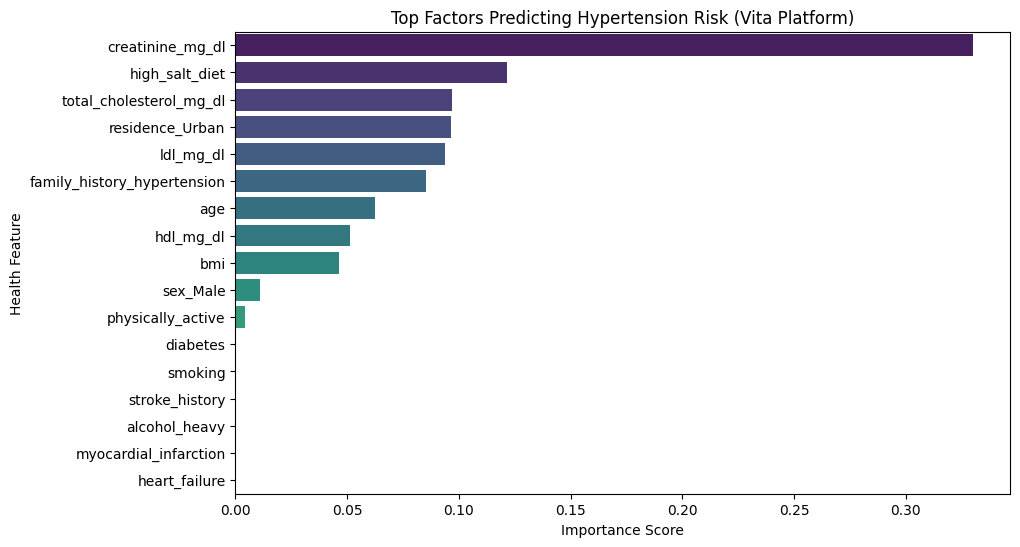

In [94]:
#  Calculate Feature Importance
importances = rf_vita.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

#  Plot Feature Importance for the Presentation
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Top Factors Predicting Hypertension Risk (Vita Platform)')
plt.xlabel('Importance Score')
plt.ylabel('Health Feature')
plt.show()

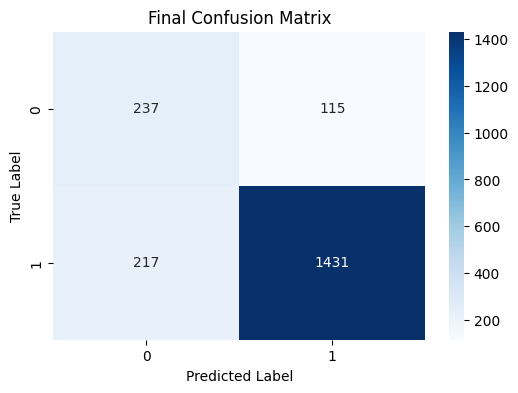

In [95]:
#  Visualizing Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, final_test_preds), annot=True, fmt='d', cmap='Blues')
plt.title('Final Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [96]:
import pickle

#  Define the filename
filename = 'hypertension_model.pkl'

#  Open a file in 'wb' (write binary) mode and save the model
# rf_vita is your trained Random Forest model
with open(filename, 'wb') as file:
    pickle.dump(rf_vita, file)

print(f"Model saved successfully as {filename}")

Model saved successfully as hypertension_model.pkl
